# HER2+ Breast Cancer Gene Expression Analysis

## 1. Data Exploration
This notebook explores the structure of the GSE245132 gene expression dataset before performing downstream analysis.

### Goals
- Load the processed GEO series matrix
- Inspect the dimensions and structure of the expression data
- Identify sample and feature information
- Prepare the data for baseline vs. post-treatment comparison


In [2]:
import pandas as pd
import numpy as np

In [3]:
import os

os.getcwd()

'/home/sis02/Projects/her2-gene-expression-analysis/notebooks'

In [4]:
data_path = "../data/GSE245132_series_matrix.txt"
os.path.exists(data_path)

True

In [5]:
expression_df = pd.read_csv(
    data_path,
    sep="\t",
    skiprows=62
) 
# expression_df는 expression matrix를 저장한 DataFrame variable
# \t는 tab 즉: 각 column은 tab으로 구분되어 있다고 pandas에게 알려주는 것
# skiprows=62는 앞의 62줄을 건너뛰고 읽어라 -> 63번째 줄인 "ID_REF" "FSM7837244" ...를 column names/header로 사용하게 됨
expression_df.head()
# DataFrame의 처음 5개 rows를 보여줌

,ID_REF,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
0,TC0100006437.hg.1,6.699491,7.023459,6.866237,6.864067,7.116156,7.154243,6.738917,6.983281,6.911802,...,7.019715,6.748944,6.868323,6.681636,6.707026,7.081187,7.180591,6.795221,6.935736,7.270319
1,TC0100006476.hg.1,5.858871,5.511078,5.757049,5.653263,5.634929,5.586172,5.651388,5.587537,5.569932,...,5.755594,5.715699,5.748914,5.759298,5.846549,5.508467,5.604463,5.795497,5.686680,5.724931
2,TC0100006479.hg.1,7.527140,7.591499,7.641178,7.312896,7.472248,7.511117,7.228207,7.559089,7.417284,...,7.666647,7.549583,7.720754,7.357933,7.510737,7.525719,7.719205,7.725928,7.518623,7.442325
3,TC0100006480.hg.1,6.642914,6.886240,6.772836,6.589355,6.950437,6.965211,6.681968,6.844155,6.572749,...,6.828575,7.108570,6.777758,6.651523,6.652452,7.013474,6.946153,6.860686,6.952366,7.149339
4,TC0100006483.hg.1,12.362670,10.831000,11.652310,11.119240,11.445440,11.684410,11.631090,11.263410,11.904260,...,11.710190,11.200480,11.331710,11.079830,12.120670,10.616840,11.950550,11.417210,11.524020,11.375900


In [6]:
expression_df.shape

(21449, 65)

In [7]:
expression_df.tail()

,ID_REF,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
21444,TSUnmapped00000820.hg.1,7.215323,6.908916,7.527110,7.148620,7.716397,7.086964,7.247353,7.044221,6.819007,...,7.368483,6.892673,7.249774,7.222658,6.754844,7.397474,6.929242,7.388697,7.324537,7.414706
21445,TSUnmapped00000821.hg.1,5.682681,5.562259,5.734435,5.939415,5.677493,5.947857,5.632574,5.588262,5.652801,...,5.742899,5.617142,5.525916,5.623251,5.640113,5.852871,5.923877,5.963168,5.694182,5.609817
21446,TSUnmapped00000822.hg.1,5.247820,5.763969,5.540705,5.572333,5.419194,5.488442,5.624328,5.646287,5.568121,...,5.573056,5.858377,5.683992,5.503022,5.345350,5.598806,5.633884,5.699905,5.382211,5.430044
21447,TSUnmapped00000823.hg.1,7.893728,7.931292,7.922690,7.960620,8.033476,8.011501,7.836545,8.060505,7.856040,...,7.889155,7.714014,7.941951,7.626719,7.628978,7.830407,8.103840,8.040696,7.881028,7.690736
21448,!series_matrix_table_end,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
expression_df["ID_REF"] != "!series_matrix_table_end"

0         True
1         True
2         True
3         True
4         True
         ...  
21444     True
21445     True
21446     True
21447     True
21448    False
Name: ID_REF, Length: 21449, dtype: bool

In [9]:
expression_df[
    expression_df["ID_REF"] != "!series_matrix_table_end"
]

,ID_REF,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
0,TC0100006437.hg.1,6.699491,7.023459,6.866237,6.864067,7.116156,7.154243,6.738917,6.983281,6.911802,...,7.019715,6.748944,6.868323,6.681636,6.707026,7.081187,7.180591,6.795221,6.935736,7.270319
1,TC0100006476.hg.1,5.858871,5.511078,5.757049,5.653263,5.634929,5.586172,5.651388,5.587537,5.569932,...,5.755594,5.715699,5.748914,5.759298,5.846549,5.508467,5.604463,5.795497,5.686680,5.724931
2,TC0100006479.hg.1,7.527140,7.591499,7.641178,7.312896,7.472248,7.511117,7.228207,7.559089,7.417284,...,7.666647,7.549583,7.720754,7.357933,7.510737,7.525719,7.719205,7.725928,7.518623,7.442325
3,TC0100006480.hg.1,6.642914,6.886240,6.772836,6.589355,6.950437,6.965211,6.681968,6.844155,6.572749,...,6.828575,7.108570,6.777758,6.651523,6.652452,7.013474,6.946153,6.860686,6.952366,7.149339
4,TC0100006483.hg.1,12.362670,10.831000,11.652310,11.119240,11.445440,11.684410,11.631090,11.263410,11.904260,...,11.710190,11.200480,11.331710,11.079830,12.120670,10.616840,11.950550,11.417210,11.524020,11.375900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21443,TSUnmapped00000819.hg.1,7.360468,7.105131,7.261381,7.076610,6.810274,6.848968,7.222497,7.087993,7.179842,...,6.961360,7.164807,7.087227,7.152398,7.335340,6.904150,6.959280,6.839369,7.192832,7.203874
21444,TSUnmapped00000820.hg.1,7.215323,6.908916,7.527110,7.148620,7.716397,7.086964,7.247353,7.044221,6.819007,...,7.368483,6.892673,7.249774,7.222658,6.754844,7.397474,6.929242,7.388697,7.324537,7.414706
21445,TSUnmapped00000821.hg.1,5.682681,5.562259,5.734435,5.939415,5.677493,5.947857,5.632574,5.588262,5.652801,...,5.742899,5.617142,5.525916,5.623251,5.640113,5.852871,5.923877,5.963168,5.694182,5.609817
21446,TSUnmapped00000822.hg.1,5.247820,5.763969,5.540705,5.572333,5.419194,5.488442,5.624328,5.646287,5.568121,...,5.573056,5.858377,5.683992,5.503022,5.345350,5.598806,5.633884,5.699905,5.382211,5.430044


In [10]:
expression_clean_df = expression_df[
    expression_df["ID_REF"] != "!series_matrix_table_end"
].copy()

In [11]:
expression_df.shape

(21449, 65)

In [12]:
expression_clean_df.shape

(21448, 65)

In [13]:
expression_clean_df.columns

Index(['ID_REF', 'GSM7837244', 'GSM7837245', 'GSM7837246', 'GSM7837247',
       'GSM7837248', 'GSM7837249', 'GSM7837250', 'GSM7837251', 'GSM7837252',
       'GSM7837253', 'GSM7837254', 'GSM7837255', 'GSM7837256', 'GSM7837257',
       'GSM7837258', 'GSM7837259', 'GSM7837260', 'GSM7837261', 'GSM7837262',
       'GSM7837263', 'GSM7837264', 'GSM7837265', 'GSM7837266', 'GSM7837267',
       'GSM7837268', 'GSM7837269', 'GSM7837270', 'GSM7837271', 'GSM7837272',
       'GSM7837273', 'GSM7837274', 'GSM7837275', 'GSM7837276', 'GSM7837277',
       'GSM7837278', 'GSM7837279', 'GSM7837280', 'GSM7837281', 'GSM7837282',
       'GSM7837283', 'GSM7837284', 'GSM7837285', 'GSM7837286', 'GSM7837287',
       'GSM7837288', 'GSM7837289', 'GSM7837290', 'GSM7837291', 'GSM7837292',
       'GSM7837293', 'GSM7837294', 'GSM7837295', 'GSM7837296', 'GSM7837297',
       'GSM7837298', 'GSM7837299', 'GSM7837300', 'GSM7837301', 'GSM7837302',
       'GSM7837303', 'GSM7837304', 'GSM7837305', 'GSM7837306', 'GSM7837307'],
  

In [14]:
sample_columns = expression_clean_df.columns[1:]

In [15]:
len(sample_columns)

64

In [16]:
!grep '!Sample_title' ../data/GSE245132_series_matrix.txt

!Sample_title	"Pt16_Baseline"	"Pt14_Baseline"	"Pt18_Baseline"	"Pt19_Post"	"Pt20_Post"	"Pt29_Post"	"Pt29_Baseline"	"Pt30_Baseline"	"Pt15_Baseline"	"Pt19_Baseline"	"Pt20_Baseline"	"Pt30_Post"	"Pt15_Post"	"Pt17_Baseline"	"Pt17_Post"	"Pt18_Post"	"Pt16_Post"	"Pt14_Post"	"Pt13_Baseline"	"Pt13_Post"	"Pt12_Baseline"	"Pt12_Post"	"Pt11_Baseline"	"Pt11_Post"	"Pt31_Baseline"	"Pt31_Post"	"Pt32_Baseline"	"Pt6_Baseline"	"Pt7_Baseline"	"Pt7_Post"	"Pt32_Post"	"Pt8_Baseline"	"Pt10_Baseline"	"Pt8_Post"	"Pt10_Post"	"Pt9_Post"	"Pt6_Post"	"Pt9_Baseline"	"Pt1_Baseline"	"Pt4_Post"	"Pt1_Post"	"Pt5_Baseline"	"Pt5_Post"	"Pt4_Baseline"	"Pt3_Post"	"Pt3_Baseline"	"Pt24_Baseline"	"Pt24_Post"	"Pt27_Baseline"	"Pt21_Post"	"Pt23_Post"	"Pt2_Baseline"	"Pt25_Post"	"Pt22_Post"	"Pt23_Baseline"	"Pt27_Post"	"Pt22_Baseline"	"Pt28_Post"	"Pt26_Baseline"	"Pt26_Post"	"Pt28_Baseline"	"Pt2_Post"	"Pt21_Baseline"	"Pt25_Baseline"


In [17]:
sample_title_line = None

with open(data_path, "r", encoding="utf-8") as file:
    for line in file:
        if line.startswith("!Sample_title"):
            sample_title_line = line
            break

In [18]:
sample_title_line[:200]

'!Sample_title\t"Pt16_Baseline"\t"Pt14_Baseline"\t"Pt18_Baseline"\t"Pt19_Post"\t"Pt20_Post"\t"Pt29_Post"\t"Pt29_Baseline"\t"Pt30_Baseline"\t"Pt15_Baseline"\t"Pt19_Baseline"\t"Pt20_Baseline"\t"Pt30_Post"\t"Pt15_Post'

In [19]:
sample_titles = sample_title_line.split("\t")[1:]

In [20]:
len(sample_titles)

64

In [21]:
sample_titles[:5]

['"Pt16_Baseline"',
 '"Pt14_Baseline"',
 '"Pt18_Baseline"',
 '"Pt19_Post"',
 '"Pt20_Post"']

In [22]:
clean_titles = []

for title in sample_titles:
    clean_titles.append(title.strip().strip('"'))

In [23]:
clean_titles[:5]

['Pt16_Baseline', 'Pt14_Baseline', 'Pt18_Baseline', 'Pt19_Post', 'Pt20_Post']

In [24]:
metadata_df = pd.DataFrame({
    "sample_id": sample_columns,
    "sample_title": clean_titles
})

In [25]:
metadata_df.head()

,sample_id,sample_title
0,GSM7837244,Pt16_Baseline
1,GSM7837245,Pt14_Baseline
2,GSM7837246,Pt18_Baseline
3,GSM7837247,Pt19_Post
4,GSM7837248,Pt20_Post


In [26]:
clean_titles[0].split("_")

['Pt16', 'Baseline']

In [27]:
patients =[]
timepoints = []

for title in clean_titles:
    parts = title.split("_")
    patients.append(parts[0])
    timepoints.append(parts[1])

In [28]:
patients[:5]

['Pt16', 'Pt14', 'Pt18', 'Pt19', 'Pt20']

In [29]:
timepoints[:5]

['Baseline', 'Baseline', 'Baseline', 'Post', 'Post']

In [30]:
metadata_df["patient"] = patients
metadata_df["timepoint"] = timepoints

In [31]:
metadata_df.head()

,sample_id,sample_title,patient,timepoint
0,GSM7837244,Pt16_Baseline,Pt16,Baseline
1,GSM7837245,Pt14_Baseline,Pt14,Baseline
2,GSM7837246,Pt18_Baseline,Pt18,Baseline
3,GSM7837247,Pt19_Post,Pt19,Post
4,GSM7837248,Pt20_Post,Pt20,Post


In [32]:
baseline_samples = metadata_df[
    metadata_df["timepoint"] == "Baseline"
].copy()

In [33]:
post_samples = metadata_df[
    metadata_df["timepoint"] == "Post"
].copy()

In [34]:
baseline_samples.shape

(32, 4)

In [35]:
post_samples.shape

(32, 4)

In [36]:
metadata_df["timepoint"].unique()

<StringArray>
['Baseline', 'Post']
Length: 2, dtype: str

### Data Cleaning and Metadata Summary

- Loaded the GEO series matrix into a Pandas DataFrame.
- Removed the `!series_matrix_table_end` row using Boolean filtering.
- The cleaned expression matrix contains 21,448 expression features and 64 samples.
- Extracted 64 GSM sample IDs from the expression matrix columns.
- Extracted and cleaned sample titles from the GEO metadata.
- Created a metadata DataFrame containing sample ID, sample title, patient ID, and timepoint.
- Confirmed 32 Baseline and 32 Post-treatment samples.

During data cleaning, one Baseline sample initially contained an extra newline character (`\n`). This was identified using `.unique()` and corrected using string cleaning.

In [37]:
baseline_samples.shape

(32, 4)

In [38]:
post_samples.shape

(32, 4)

In [39]:
metadata_df["timepoint"].unique()

<StringArray>
['Baseline', 'Post']
Length: 2, dtype: str

## 2. Gene Annotation

The expression matrix contains plat-form-specific feature IDs rather than gene symbols. The platform information and annotation are needed to connect these features to genes.

In [40]:
!grep '!Series_platform_id' ../data/GSE245132_series_matrix.txt

!Series_platform_id	"GPL23159"


In [41]:
!grep '!Series_platform' ../data/GSE245132_series_matrix.txt

!Series_platform_id	"GPL23159"
!Series_platform_taxid	"9606"


- GEO platform: GPL23159
- Organism taxonomy ID: 9606 (Homo sapiens)
- The GPL23159 platform table uses `ID` values that match the `ID_REF` format in the expression matrix.
- The platform table does not provide a separate gene-symbol column, so the annotation structure needs further inspection before mapping features to genes.

In [42]:
!ls -lh ../data/

total 124M
-rw-r--r-- 1 sis02 sis02 112M Sep 22 19:30 GPL23159_annotation.txt
-rw-r--r-- 1 sis02 sis02   25 Sep 22 19:30 GPL23159_annotation.txt:Zone.Identifier
-rw-r--r-- 1 sis02 sis02  13M Jul 30 00:47 GSE245132_series_matrix.txt


In [43]:
!head ../data/GPL23159_annotation.txt

#ID = Affymetrix transcript cluster id
#probeset_id = 
#seqname = 
#strand = 
#start = 
#stop = 
#total_probes = 
#category = 
#SPOT_ID = locus type & mrna_assignment
#SPOT_ID = 


In [44]:
!grep -n '^ID' ../data/GPL23159_annotation.txt | head

11:ID	probeset_id	seqname	strand	start	stop	total_probes	category	SPOT_ID	SPOT_ID


In [45]:
!sed -n '11,14p' ../data/GPL23159_annotation.txt

ID	probeset_id	seqname	strand	start	stop	total_probes	category	SPOT_ID	SPOT_ID
TC0100006437.hg.1	TC0100006437.hg.1	chr1	+	69091	70008	10	main	Coding	NM_001005484 // RefSeq // Homo sapiens olfactory receptor, family 4, subfamily F, member 5 (OR4F5), mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000335137 // ENSEMBL // olfactory receptor, family 4, subfamily F, member 5 [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// OTTHUMT00000003223 // Havana transcript // olfactory receptor, family 4, subfamily F, member 5[gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// uc001aal.1 // UCSC Genes // Homo sapiens olfactory receptor, family 4, subfamily F, member 5 (OR4F5), mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// CCDS30547.1 // ccdsGene // olfactory receptor, family 4, subfamily F, member 5 [Source:HGNC Symbol;Acc:HGNC:14825] // chr1 // 100 // 100 // 0 // --- // 0
TC01000

In [46]:
!grep -n 'ERBB2' ../data/GPL23159_annotation.txt

5538:TC0500007610.hg.1	TC0500007610.hg.1	chr5	+	65926475	66082549	10	main	Multiple_Complex	NM_001006600 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 7, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253697 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 1, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253698 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 4, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253699 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 8, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253701 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 9, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_018695 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 2, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// ENST00000284037 // ENSEMBL // 

In [47]:
expression_clean_df[expression_clean_df["ID_REF"] == 'TC1700012249.hg.1']

,ID_REF,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
17680,TC1700012249.hg.1,12.66088,10.55717,10.12421,10.47789,9.44921,8.757608,10.99382,11.00916,10.7875,...,11.71837,10.00084,10.4516,10.90028,13.21521,9.085446,10.3573,10.27419,10.50616,10.0276


In [48]:
expression_clean_df[expression_clean_df["ID_REF"] == 'TC1700012250.hg.1']

,ID_REF,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
17681,TC1700012250.hg.1,10.31529,8.906538,8.955875,8.969745,8.74032,7.914842,8.815448,9.370032,9.316257,...,9.096941,8.184332,9.199963,9.238185,10.61325,7.949407,8.885191,8.577633,8.970407,8.190205


### Identifying ERBB2-Related Features

The GPL23159 annotation was searched to identify platform features associated with ERBB2. Because a simple text search also returns genes whose annotations merely contain the term "ERBB2", candidate features must be inspected before selecting a feature for expression analysis.

In [49]:
!grep -n 'ERBB2' ../data/GPL23159_annotation.txt

5538:TC0500007610.hg.1	TC0500007610.hg.1	chr5	+	65926475	66082549	10	main	Multiple_Complex	NM_001006600 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 7, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253697 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 1, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253698 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 4, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253699 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 8, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_001253701 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 9, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// NM_018695 // RefSeq // Homo sapiens erbb2 interacting protein (ERBB2IP), transcript variant 2, mRNA. // chr5 // 100 // 100 // 0 // --- // 0 /// ENST00000284037 // ENSEMBL // 

The search identified two candidate features with direct ERBB2-related annotations: `TC1700012249.hg.1` and `TC1700012250.hg.1`. Both features were confirmed to be present in the GSE245132 expression matrix. Inspection of the platform annotations showed that `TC1700012249.hg.1` includes multiple protein-coding ERBB2 transcripts, whereas `TC1700012250.hg.1` is categorized as a non-coding feature.

In [50]:
expression_clean_df[
    expression_clean_df["ID_REF"] == "TC1700012249.hg.1"
]

,ID_REF,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
17680,TC1700012249.hg.1,12.66088,10.55717,10.12421,10.47789,9.44921,8.757608,10.99382,11.00916,10.7875,...,11.71837,10.00084,10.4516,10.90028,13.21521,9.085446,10.3573,10.27419,10.50616,10.0276


In [51]:
expression_clean_df[
    expression_clean_df["ID_REF"] == "TC1700012250.hg.1"
]

,ID_REF,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
17681,TC1700012250.hg.1,10.31529,8.906538,8.955875,8.969745,8.74032,7.914842,8.815448,9.370032,9.316257,...,9.096941,8.184332,9.199963,9.238185,10.61325,7.949407,8.885191,8.577633,8.970407,8.190205


After inspecting the candidate annotations, `TC1700012249.hg.1` was selected as the ERBB2-associated transcript cluster for this exploratory analysis because its annotation includes multiple protein-coding ERBB2 transcripts. Because the annotation is complex and also contains MIR4728-related information, this feature is treated as ERBB2-associated rather than strictly ERBB2-specific.

In [52]:
expression_clean_df[sample_columns]

,GSM7837244,GSM7837245,GSM7837246,GSM7837247,GSM7837248,GSM7837249,GSM7837250,GSM7837251,GSM7837252,GSM7837253,...,GSM7837298,GSM7837299,GSM7837300,GSM7837301,GSM7837302,GSM7837303,GSM7837304,GSM7837305,GSM7837306,GSM7837307
0,6.699491,7.023459,6.866237,6.864067,7.116156,7.154243,6.738917,6.983281,6.911802,7.013233,...,7.019715,6.748944,6.868323,6.681636,6.707026,7.081187,7.180591,6.795221,6.935736,7.270319
1,5.858871,5.511078,5.757049,5.653263,5.634929,5.586172,5.651388,5.587537,5.569932,5.455007,...,5.755594,5.715699,5.748914,5.759298,5.846549,5.508467,5.604463,5.795497,5.686680,5.724931
2,7.527140,7.591499,7.641178,7.312896,7.472248,7.511117,7.228207,7.559089,7.417284,7.598570,...,7.666647,7.549583,7.720754,7.357933,7.510737,7.525719,7.719205,7.725928,7.518623,7.442325
3,6.642914,6.886240,6.772836,6.589355,6.950437,6.965211,6.681968,6.844155,6.572749,6.934290,...,6.828575,7.108570,6.777758,6.651523,6.652452,7.013474,6.946153,6.860686,6.952366,7.149339
4,12.362670,10.831000,11.652310,11.119240,11.445440,11.684410,11.631090,11.263410,11.904260,12.141520,...,11.710190,11.200480,11.331710,11.079830,12.120670,10.616840,11.950550,11.417210,11.524020,11.375900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21443,7.360468,7.105131,7.261381,7.076610,6.810274,6.848968,7.222497,7.087993,7.179842,7.001287,...,6.961360,7.164807,7.087227,7.152398,7.335340,6.904150,6.959280,6.839369,7.192832,7.203874
21444,7.215323,6.908916,7.527110,7.148620,7.716397,7.086964,7.247353,7.044221,6.819007,7.289504,...,7.368483,6.892673,7.249774,7.222658,6.754844,7.397474,6.929242,7.388697,7.324537,7.414706
21445,5.682681,5.562259,5.734435,5.939415,5.677493,5.947857,5.632574,5.588262,5.652801,5.669487,...,5.742899,5.617142,5.525916,5.623251,5.640113,5.852871,5.923877,5.963168,5.694182,5.609817
21446,5.247820,5.763969,5.540705,5.572333,5.419194,5.488442,5.624328,5.646287,5.568121,5.529481,...,5.573056,5.858377,5.683992,5.503022,5.345350,5.598806,5.633884,5.699905,5.382211,5.430044


In [53]:
expression_clean_df[sample_columns].shape

(21448, 64)

In [54]:
erbb2_values = expression_clean_df[expression_clean_df["ID_REF"] == "TC1700012249.hg.1"][sample_columns]

In [55]:
erbb2_values.shape

(1, 64)

In [56]:
erbb2_values.T

,17680
GSM7837244,12.660880
GSM7837245,10.557170
GSM7837246,10.124210
GSM7837247,10.477890
GSM7837248,9.449210
...,...
GSM7837303,9.085446
GSM7837304,10.357300
GSM7837305,10.274190
GSM7837306,10.506160


In [57]:
erbb2_values.T.reset_index()

,index,17680
0,GSM7837244,12.660880
1,GSM7837245,10.557170
2,GSM7837246,10.124210
3,GSM7837247,10.477890
4,GSM7837248,9.449210
...,...,...
59,GSM7837303,9.085446
60,GSM7837304,10.357300
61,GSM7837305,10.274190
62,GSM7837306,10.506160


In [58]:
erbb2_expression_df = erbb2_values.T.reset_index()

In [59]:
erbb2_expression_df.columns = ["sample_id", "ERBB2_expression"]

In [60]:
erbb2_expression_df.head()

,sample_id,ERBB2_expression
0,GSM7837244,12.66088
1,GSM7837245,10.55717
2,GSM7837246,10.12421
3,GSM7837247,10.47789
4,GSM7837248,9.44921


In [61]:
analysis_df = metadata_df.merge(
    erbb2_expression_df,
    on="sample_id"
)

In [62]:
analysis_df.shape

(64, 5)

In [63]:
analysis_df.head()

,sample_id,sample_title,patient,timepoint,ERBB2_expression
0,GSM7837244,Pt16_Baseline,Pt16,Baseline,12.66088
1,GSM7837245,Pt14_Baseline,Pt14,Baseline,10.55717
2,GSM7837246,Pt18_Baseline,Pt18,Baseline,10.12421
3,GSM7837247,Pt19_Post,Pt19,Post,10.47789
4,GSM7837248,Pt20_Post,Pt20,Post,9.44921


In [64]:
analysis_df.groupby("patient").size()

patient
Pt1     2
Pt10    2
Pt11    2
Pt12    2
Pt13    2
Pt14    2
Pt15    2
Pt16    2
Pt17    2
Pt18    2
Pt19    2
Pt2     2
Pt20    2
Pt21    2
Pt22    2
Pt23    2
Pt24    2
Pt25    2
Pt26    2
Pt27    2
Pt28    2
Pt29    2
Pt3     2
Pt30    2
Pt31    2
Pt32    2
Pt4     2
Pt5     2
Pt6     2
Pt7     2
Pt8     2
Pt9     2
dtype: int64

In [65]:
analysis_df[["patient", "timepoint"]].head(10)

,patient,timepoint
0,Pt16,Baseline
1,Pt14,Baseline
2,Pt18,Baseline
3,Pt19,Post
4,Pt20,Post
5,Pt29,Post
6,Pt29,Baseline
7,Pt30,Baseline
8,Pt15,Baseline
9,Pt19,Baseline


In [66]:
analysis_df.groupby("patient")["timepoint"].unique()

patient
Pt1     [Baseline, Post]
Pt10    [Baseline, Post]
Pt11    [Baseline, Post]
Pt12    [Baseline, Post]
Pt13    [Baseline, Post]
Pt14    [Baseline, Post]
Pt15    [Baseline, Post]
Pt16    [Baseline, Post]
Pt17    [Baseline, Post]
Pt18    [Baseline, Post]
Pt19    [Post, Baseline]
Pt2     [Baseline, Post]
Pt20    [Post, Baseline]
Pt21    [Post, Baseline]
Pt22    [Post, Baseline]
Pt23    [Post, Baseline]
Pt24    [Baseline, Post]
Pt25    [Post, Baseline]
Pt26    [Baseline, Post]
Pt27    [Baseline, Post]
Pt28    [Post, Baseline]
Pt29    [Post, Baseline]
Pt3     [Post, Baseline]
Pt30    [Baseline, Post]
Pt31    [Baseline, Post]
Pt32    [Baseline, Post]
Pt4     [Post, Baseline]
Pt5     [Baseline, Post]
Pt6     [Baseline, Post]
Pt7     [Baseline, Post]
Pt8     [Baseline, Post]
Pt9     [Post, Baseline]
Name: timepoint, dtype: object

In [67]:
paired_df = analysis_df.pivot(
    index="patient",
    columns="timepoint",
    values="ERBB2_expression"
)

paired_df.head()

timepoint,Baseline,Post
patient,,
Pt1,12.02234,11.533330
Pt10,13.02395,8.553489
Pt11,10.92539,9.842330
Pt12,10.69361,11.874160
Pt13,12.36829,11.853020


In [68]:
paired_df.shape

(32, 2)

## 3. Preparing Paired Expression Data

ERBB2-associated expression values were linked to the sample metadata using the GSM sample IDs. The dataset was then reshaped so that each row represents one patient, with separate columns for Baseline and Post-treatment expression. This enables paired comparison of expression before and after treatment.

### Descriptive Statistics

In [69]:
paired_df["Baseline"].mean()

np.float64(11.245117500000001)

In [70]:
paired_df["Post"].mean()

np.float64(10.03742259375)

In [71]:
paired_df["Baseline"].median()

np.float64(10.963384999999999)

In [72]:
paired_df["Post"].median()

np.float64(9.968999499999999)

In [73]:
paired_df["change"] = paired_df["Post"] - paired_df["Baseline"]

paired_df.head()

timepoint,Baseline,Post,change
patient,,,
Pt1,12.02234,11.533330,-0.489010
Pt10,13.02395,8.553489,-4.470461
Pt11,10.92539,9.842330,-1.083060
Pt12,10.69361,11.874160,1.180550
Pt13,12.36829,11.853020,-0.515270


In [74]:
paired_df["change"] < 0

patient
Pt1      True
Pt10     True
Pt11     True
Pt12    False
Pt13     True
Pt14     True
Pt15     True
Pt16     True
Pt17     True
Pt18    False
Pt19     True
Pt2      True
Pt20     True
Pt21     True
Pt22    False
Pt23     True
Pt24    False
Pt25     True
Pt26     True
Pt27     True
Pt28    False
Pt29     True
Pt3      True
Pt30     True
Pt31     True
Pt32     True
Pt4      True
Pt5      True
Pt6      True
Pt7     False
Pt8      True
Pt9      True
Name: change, dtype: bool

In [75]:
(paired_df["change"] < 0).sum()

np.int64(26)

In [76]:
(paired_df["change"] > 0).sum()

np.int64(6)

In [77]:
(paired_df["change"] == 0).sum()

np.int64(0)

In [78]:
paired_df["change"].mean()

np.float64(-1.20769490625)

In [79]:
paired_df["change"].median()

np.float64(-0.7971424999999996)

In [80]:
paired_df["change"].min()

np.float64(-4.4704609999999985)

In [81]:
paired_df[paired_df["change"] == paired_df["change"].min()]

timepoint,Baseline,Post,change
patient,,,
Pt10,13.02395,8.553489,-4.470461


In [82]:
# Find patients with the largest decreases in expression
paired_df.sort_values("change").head()

timepoint,Baseline,Post,change
patient,,,
Pt10,13.02395,8.553489,-4.470461
Pt26,13.21521,9.085446,-4.129764
Pt16,12.66088,8.571925,-4.088955
Pt17,12.47353,9.241368,-3.232162
Pt20,12.10723,9.449210,-2.658020


**Observation**

Several patients, including Pt10, Pt26, and Pt16, showed relatively large decreases in ERBB2-associated expression. These decreases may help explain why the mean change (-1.21) was more negative than the median (-0.80).

In [83]:
paired_df["change"].std()

np.float64(1.474223216941752)

In [84]:
standard_effor = paired_df["change"].std() / np.sqrt(len(paired_df["change"]))

standard_effor

np.float64(0.2606083084205399)

## 4. Exploratory Data Visualization

### Distribution of Paired ERBB2 Expression Changes

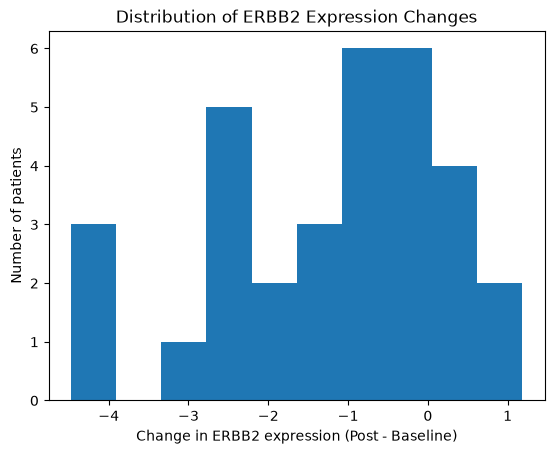

In [85]:
import matplotlib.pyplot as plt

plt.hist(paired_df["change"])
plt.xlabel("Change in ERBB2 expression (Post - Baseline)")
plt.ylabel("Number of patients")
plt.title("Distribution of ERBB2 Expression Changes")
plt.show()

**Observation**

The histogram shows the distribution of paired ERBB2-associated expression changes across 32 patients, calculated as Post - Baseline.

Most patients showed negative expression changes (26 out of 32), indicating that decreases were more common than increases.

The mean change was approximately -1.21, while the median change was approximately -0.80. The more negative mean suggests that relatively large decreases in some patients may have influenced the average.

Although the overall pattern suggests a decrease in ERBB2-associated expression after treatment, the magnitude and direction of change varied across patients.

### Visualizing Individual Patient Changes

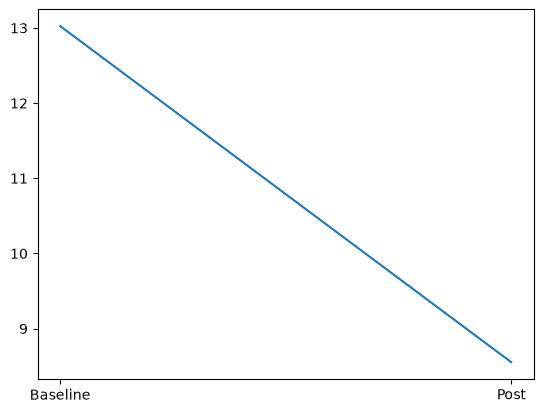

In [86]:
plt.plot(
    ["Baseline", "Post"],
    [13.02395, 8.55349]
)
plt.show()

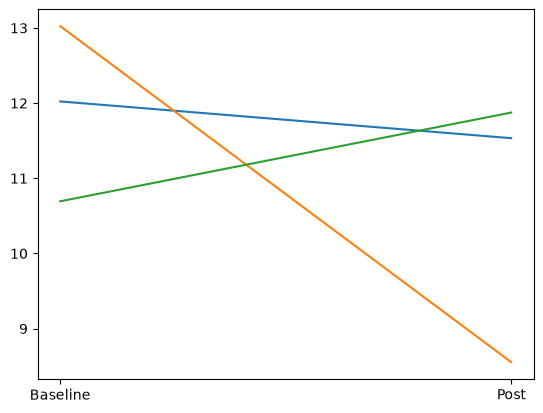

In [87]:
# Compare paired expression values for three selected patients
for patient in ["Pt1", "Pt10", "Pt12"]:
    baseline = paired_df.loc[patient, "Baseline"]
    post = paired_df.loc[patient, "Post"]

    # Connect Baseline and Post measurements for each patient
    plt.plot(["Baseline", "Post"], [baseline, post])

**Observation**

The selected patients showed different patterns of ERBB2-associated expression change between Baseline and Post-treatment.

Pt1 and Pt10 showed decreases, with a larger decrease observed in Pt10, while Pt12 showed an increase.

These examples illustrate patient-level variability and do not necessarily represent the overall distribution across all 32 patients.

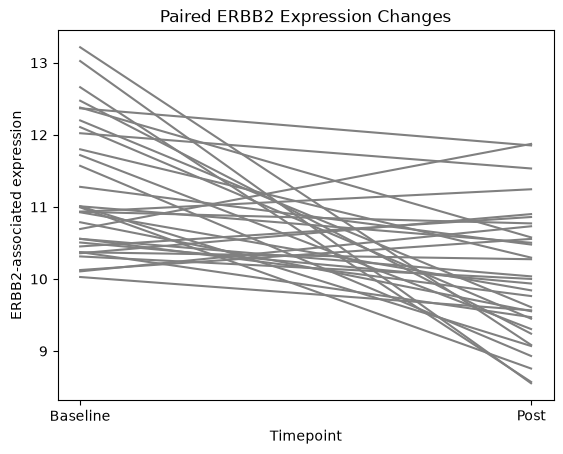

In [88]:
for patient in paired_df.index:
    baseline = paired_df.loc[patient, "Baseline"]
    post = paired_df.loc[patient, "Post"]

    plt.plot(["Baseline", "Post"],
             [baseline, post],
             color="gray"
    )

plt.xlabel("Timepoint")
plt.ylabel("ERBB2-associated expression")
plt.title("Paired ERBB2 Expression Changes")
plt.show()

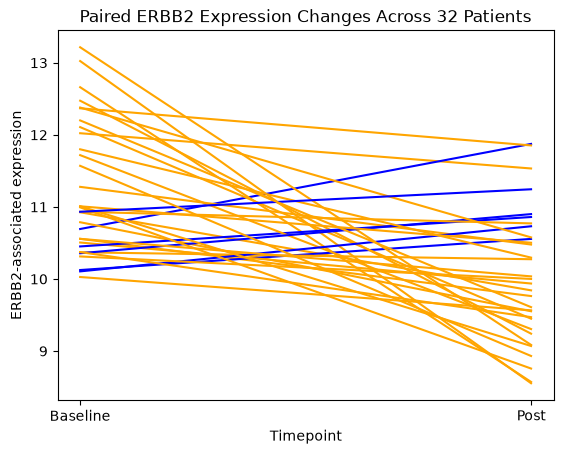

In [89]:
for patient in paired_df.index:
    baseline = paired_df.loc[patient, "Baseline"]
    post = paired_df.loc[patient, "Post"]

    if post > baseline:
        color = "blue"
    else:
        color = "orange"

    plt.plot(["Baseline", "Post"], [baseline, post], color=color)

plt.xlabel("Timepoint")
plt.ylabel("ERBB2-associated expression")
plt.title("Paired ERBB2 Expression Changes Across 32 Patients")
plt.show()

**Observation**

The paired line plot shows ERBB2-associated expression changes across all 32 patients.

Color coding distinguishes patients with decreased expression (orange) from those with increased expression (blue). Overall, 26 patients showed decreases, while 6 showed increases.

Although the color coding makes the direction of change easier to identify, overlapping lines make it difficult to distinguish each patient's change clearly and compare how much their expression changed.

This suggests that an additional visualization may be useful for summarizing patient-level variability.

## 5. Statistical Analysis

### Hypothesis

- H0: The population mean paired change in ERBB2-associated expression is zero
- H1: The population mean paired change in ERBB2-associated expression is not zero

The paired change is defined as Post - Baseline

### Paired t-test

A paired t-test is used to evaluate whether the mean ERBB2-associated expression change between Baseline and Post differs from zero.

Because Baseline and Post measurements come from the same 32 patients, the observations are paired rather than independent.

We use `scipy.stats.ttest_rel()` to perform the test.

- `scipy.stats`: A Python module for statistical analysis
- `ttest_rel()`: Performs a paired t-test on two related measurements.
- Input order: Post first, Baseline second consistent with the definition of change = Post - Baseline
- Output: t-statistic, p-value, and degrees of freedon (df)

In [92]:
# Import Scipy's statistical analysis module
from scipy import stats

In [93]:
# Paired t-test: compare Post v.s Baseline measurements from the smae patients
# The test uses Post - Baseline to match our definition of paired change
stats.ttest_rel(paired_df["Post"], paired_df["Baseline"])

TtestResult(statistic=np.float64(-4.634138157641391), pvalue=np.float64(6.112545392733135e-05), df=np.int64(31))

### Statistical Results and Interpretation

A two-sided paired t-test was performed to evaluate whether the mean ERBB2-associated expression change (Post - Baseline) differed from zero.

- Sample size: 32 paired patients
- Mean paired change: -1.2077
- t-statistic: -4.6341
- Degrees of freedom (df): 31
- p-value:  6.11 × 10⁻⁵
- Significance level (α): 0.05

The p-value is below 0.05, so we reject the null hypothesis that the population mean paired change is zero.

The results provide statiscally significant evidence of difference in mean ERBB2-associated expression between Baseline and Post. The observed mean change was negative, indicating lower expression at Post on average in the analyzed sample.

Limitations: Statistical significance does not establish that treatment caused the observed change, nor does it imply that every patient experienced a decrease. The analysis concerns an ERBB2-associated microarray feature rather than a direct measurement of HER2 protein abundance.